# Semana 2 · Arquitecturas de Deep Learning para texto: normalización de nombres de cantón con BiGRU y Transformer
**MCDA · UIDE · Grupo 10 · Tema 50:** *Consolidación territorial de datos abiertos gubernamentales ecuatorianos mediante data lake y detección de anomalías*
**Integrantes:** Wilson Paredes, Diana Tandalla, Alexander Luna y Bryan Sarmiento

**Problema (rúbrica 1).** En el data lake de la tesis, el campo «cantón» llega con errores de escritura, abreviaturas, codificación rota y nombres alternativos. Un cantón mal escrito no se une al catálogo oficial (DPA) y se pierde del análisis territorial. Se plantea una **clasificación de texto a nivel de caracteres**: dado el texto crudo de un cantón, predecir cuál de los **219 nombres de cantón oficiales** es (221 cantones; Bolívar y Olmedo se repiten en dos provincias y comparten clase).

**Por qué una arquitectura recurrente o de atención (y no una CNN ni un MLP).** El texto es una *secuencia corta de caracteres* (unos 12 caracteres de media) donde el orden importa («PIAS» ≠ «SAIP») y los errores son locales (una letra de menos, un espacio de más). Una RNN bidireccional (GRU) lee la cadena en ambos sentidos y resume el contexto; un Transformer con atención y codificación posicional relaciona cualquier par de caracteres sin recorrido secuencial. Trabajar con **caracteres y no con palabras** evita un vocabulario cerrado: «MARIDUEA» o «MCHALA» nunca aparecieron en el entrenamiento como palabras, pero comparten casi todos sus caracteres con el nombre correcto.

**Alcance.** Se implementan **desde cero en Keras/TensorFlow** dos arquitecturas (sin pesos preentrenados): *BiGRU* y *Transformer encoder*, y se comparan con una línea base sin aprendizaje (distancia de edición). La evaluación usa una prueba sintética y, sobre todo, una **prueba real**: las variantes de cantón que el equipo corrigió a mano en el EDA (`diccionario_correccion_canton.csv`), que nunca se usan para entrenar.

In [1]:
import os, re, json, unicodedata, random, warnings, time, sys, itertools, collections
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
try:
    from rapidfuzz import process, fuzz
except ImportError:                                   # rapidfuzz solo acelera la línea base
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz"]); from rapidfuzz import process, fuzz
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

PAR = dict(SEMILLA=42, SEMILLAS_EXTRA=[1, 2], VARIANTES_POR_CLASE=80, FRAC_VAL=0.15, FRAC_TEST=0.15, MAXLEN=40,
           EMB=64, GRU=96, D_MODELO=64, CABEZAS=4, FF=128, BLOQUES=2, DROPOUT=0.3, LR=1e-3, BATCH=128, EPOCAS=60, PACIENCIA=6, UMBRAL_CONF=0.50)
RES = {"parametros": PAR, "versiones": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
def fijar_semilla(s): random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
fijar_semilla(PAR["SEMILLA"])
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.13.2


## 1. Datos de la tesis
Tres insumos del data lake (carpeta `datos/`):
* `dpa_cantones.csv`: catálogo oficial del INEC (221 cantones, con el nombre de la cabecera cantonal).
* `territory.parquet`: valores territoriales distintos encontrados en los 890 archivos del data lake, con su número de registros (`n`).
* `diccionario_correccion_canton.csv`: 50 variantes que **no** se pudieron homologar con reglas y que el equipo resolvió a mano (cantón oficial sugerido). Es la **verdad de terreno real**.

La función `nrm` es la misma normalización del pipeline del data lake (mayúsculas, sin tildes, sin signos). Todo el texto entra normalizado a la red.

In [2]:
def nrm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9 ]", " ", s)).strip()

dpa = pd.read_csv("https://raw.githubusercontent.com/Alexander-Luna/NeuralNetworks-DeepLearning/7b9a54df146caf4a97c3697754f0ca6596624938/SEMANA%202/datos/dpa_cantones.csv", dtype=str)
terr = pd.read_parquet("https://github.com/Alexander-Luna/NeuralNetworks-DeepLearning/raw/7b9a54df146caf4a97c3697754f0ca6596624938/SEMANA%202/datos/territory.parquet"); terr = terr[terr.rol == "cantón"].copy(); terr["vn"] = terr.valor.map(nrm)
dic = pd.read_csv("https://raw.githubusercontent.com/Alexander-Luna/NeuralNetworks-DeepLearning/7b9a54df146caf4a97c3697754f0ca6596624938/SEMANA%202/datos/diccionario_correccion_canton.csv", encoding="utf-8-sig"); dic["x"] = dic.valor.map(nrm); dic["y"] = dic.canton_oficial_sugerido.map(nrm)

CLASES = sorted(set(dpa.canton_norm)); C2I = {c: i for i, c in enumerate(CLASES)}; NC = len(CLASES)
# alias oficiales: nombre de la cabecera cantonal cuando difiere del nombre del cantón (misma regla que el EDA)
alias = {}
for cab, k in zip(dpa.cabecera_norm, dpa.canton_norm):
    if isinstance(cab, str) and cab not in C2I: alias[cab] = k
for cab, k in list(alias.items()):
    b = nrm(re.sub(r"\(.*\)|CABECERA CANTONAL", "", cab))
    if b and b not in C2I: alias.setdefault(b, k)
alias = {nrm(a): k for a, k in alias.items() if nrm(a) not in C2I}
fuentes = [(c, c) for c in CLASES] + [(a, k) for a, k in alias.items()]      # (texto base, clase)

# prueba real: cadenas distintas normalizadas del diccionario manual (se suman sus registros)
real = dic.groupby(["x", "y"], as_index=False).agg(registros=("registros", "sum"), variantes_crudas=("valor", "nunique"))
assert real.x.is_unique and set(real.y) <= set(CLASES)
n_reg_canton = int(terr.n.sum())
RES["datos"] = dict(cantones_oficiales=len(dpa), clases=NC, alias_cabecera=len(alias), textos_crudos_distintos=int(terr.valor.nunique()),
                    textos_normalizados_distintos=int(terr.vn.nunique()), registros_con_canton=n_reg_canton,
                    dic_filas=len(dic), dic_cadenas_distintas=len(real), dic_registros=int(dic.registros.sum()),
                    dic_pct_registros=round(float(dic.registros.sum() / n_reg_canton * 100), 2))
print(RES["datos"]); display(real.sort_values("registros", ascending=False).head(8))

{'cantones_oficiales': 221, 'clases': 219, 'alias_cabecera': 58, 'textos_crudos_distintos': 1078, 'textos_normalizados_distintos': 701, 'registros_con_canton': 6336984, 'dic_filas': 50, 'dic_cadenas_distintas': 38, 'dic_registros': 19104, 'dic_pct_registros': 0.3}


,x,y,registros,variantes_crudas
27,PUERTO FRANCISCO DE ORELLANA,FRANCISCO DE ORELLANA,5250,2
28,RIO VERDE,RIOVERDE,2979,3
24,PUEBLO VIEJO,PUEBLOVIEJO,2780,2
13,GNRAL ANTONIO ELIZALDE,GENERAL ANTONIO ELIZALDE,2543,1
10,CRNEL MARCELINO MARIDUEA,CORONEL MARCELINO MARIDUENA,1867,3
15,JOYA DE LOS SACHAS,LA JOYA DE LOS SACHAS,827,1
6,CAMILO PONCE ENRIQUE,CAMILO PONCE ENRIQUEZ,739,1
12,CRNEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,719,2


## 2. Construcción del corpus de entrenamiento
Solo hay 219 nombres oficiales (más 58 alias de cabecera): demasiado pocos para entrenar una red. Se genera un corpus **sintético con ruido realista** a partir de esos nombres, con cinco familias de error propias de los datos abiertos ecuatorianos:

| Familia | Qué simula | Ejemplo |
|---|---|---|
| `edit` | errores de digitación: borrar, insertar, sustituir o transponer 1–3 letras | MACHALA → MCHALA |
| `espacio` | espacios omitidos o de más | ROCAFUERTE → ROCA FUERTE |
| `codif` | letras acentuadas o Ñ dañadas por codificación (se pierden, se sustituyen por A o por espacio) | BAÑOS → BAOS |
| `abrev` | abreviaturas: se eliminan vocales interiores o se trunca una palabra | CORONEL → CRNEL |
| `tokens` | se omite una palabra de enlace o se añade un prefijo institucional | LA CONCORDIA → CONCORDIA |

**Transparencia sobre el diseño.** Las familias se definieron con conocimiento general de estos errores y de lo visto en el EDA (codificación rota, abreviaturas). El diccionario de 50 correcciones **no se usó para ajustar el generador**: sus cadenas se excluyen del corpus. No se midió cuánto depende el resultado de haber incluido estas familias (por ejemplo, entrenando solo con `edit` y `espacio`); es un límite del estudio.

In [3]:
STOP = ["DE", "LA", "LAS", "LOS", "EL", "DEL"]
PREFIJOS = ["CANTON", "CIUDAD", "CABECERA CANTONAL", "MUNICIPIO DE", "GAD"]
LETRAS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
VECINAS = {"Q": "WA", "W": "QES", "E": "WRD", "R": "ETF", "T": "RYG", "Y": "TUH", "U": "YIJ", "I": "UOK", "O": "IPL", "P": "O", "A": "QSZ", "S": "ADW", "D": "SFE", "F": "DGR", "G": "FHT",
           "H": "GJY", "J": "HKU", "K": "JLI", "L": "KO", "Z": "AX", "X": "ZC", "C": "XV", "V": "CB", "B": "VN", "N": "BM", "M": "N"}

def op_edit(s, rng):
    for _ in range(int(rng.choice([1, 2, 3], p=[0.55, 0.35, 0.10]))):
        if len(s) < 3: break
        i = int(rng.integers(len(s))); t = rng.choice(["del", "ins", "sub", "swap"])
        if t == "del": s = s[:i] + s[i + 1:]
        elif t == "ins": s = s[:i] + str(rng.choice(LETRAS)) + s[i:]
        elif t == "sub" and s[i] != " ": s = s[:i] + str(rng.choice(list(VECINAS.get(s[i], "AEIOU")) + LETRAS)) + s[i + 1:]
        elif t == "swap" and i + 1 < len(s): s = s[:i] + s[i + 1] + s[i] + s[i + 2:]
    return s
def op_espacio(s, rng):
    t = rng.choice(["quitar", "quitar_todos", "agregar"])
    esp = [i for i, ch in enumerate(s) if ch == " "]
    if t == "quitar" and esp: i = int(rng.choice(esp)); return s[:i] + s[i + 1:]
    if t == "quitar_todos": return s.replace(" ", "")
    if t == "agregar" and len(s) > 4:
        i = int(rng.integers(2, len(s) - 1)); return s if " " in (s[i - 1], s[i]) else s[:i] + " " + s[i:]
    return s
def op_codif(s, rng):
    pos = [i for i, ch in enumerate(s) if ch in "NAEIOU"]
    if not pos: return s
    i = int(rng.choice([p for p in pos if s[p] == "N"] or pos)); r = rng.choice(["perder", "A", "espacio", "AA"])
    return s[:i] + {"perder": "", "A": "A", "espacio": " ", "AA": "AA"}[str(r)] + s[i + 1:]
def op_abrev(s, rng):
    pal = s.split(); largas = [i for i, p in enumerate(pal) if len(p) >= 5]
    if not largas: return s
    i = int(rng.choice(largas)); p = pal[i]; t = rng.choice(["vocales", "truncar", "inicial"])
    if t == "vocales": p = p[0] + "".join(ch for ch in p[1:-1] if ch not in "AEIOU" or rng.random() < 0.3) + p[-1]
    elif t == "truncar": p = p[:int(rng.integers(3, max(4, len(p) - 1)))]
    else: p = p[0]
    pal[i] = p; return " ".join(pal)
def op_tokens(s, rng):
    pal = s.split(); t = rng.choice(["quitar", "prefijo"])
    cand = [i for i, p in enumerate(pal) if p in STOP]
    if t == "quitar" and cand: pal.pop(int(rng.choice(cand))); return " ".join(pal)
    return str(rng.choice(PREFIJOS)) + " " + s
FAMILIAS = {"edit": op_edit, "espacio": op_espacio, "codif": op_codif, "abrev": op_abrev, "tokens": op_tokens}
TODAS, BASICAS = ["edit", "espacio", "codif", "abrev", "tokens"], ["edit", "espacio"]
PESOS = {"edit": 0.40, "espacio": 0.15, "codif": 0.20, "abrev": 0.15, "tokens": 0.10}

from rapidfuzz.distance import Levenshtein
def variante(base, rng, fams):
    """Aplica 1-2 operaciones de ruido; exige que el resultado siga siendo reconocible (distancia ≤ 30 % del nombre) salvo prefijos institucionales."""
    p = np.array([PESOS[f] for f in fams]); p = p / p.sum()
    for _ in range(8):
        v, usa_prefijo = base, False
        for _ in range(int(rng.choice([1, 2], p=[0.75, 0.25]))):
            f = str(rng.choice(fams, p=p)); v = FAMILIAS[f](v, rng); usa_prefijo |= (f == "tokens")
        v = nrm(v); core = v
        for pf in PREFIJOS: core = core[len(pf) + 1:] if core.startswith(pf + " ") else core
        if Levenshtein.distance(core, nrm(base)) <= max(1, int(0.3 * len(base))): return v
    return nrm(base)

def generar_corpus(fams, semilla, n_por_clase=PAR["VARIANTES_POR_CLASE"]):
    rng = np.random.default_rng(semilla); vistos = {}
    prohibidas = set(real.x)                                   # nada de la prueba real entra al corpus
    for base, clase in fuentes:
        vistos.setdefault(base, set()).add(clase)
        for _ in range(n_por_clase if base == clase else n_por_clase // 2):
            v = variante(base, rng, fams)
            if len(v) >= 2 and v not in prohibidas: vistos.setdefault(v, set()).add(clase)
    filas = [(t, next(iter(c))) for t, c in vistos.items() if len(c) == 1]          # se descartan cadenas ambiguas
    df = pd.DataFrame(filas, columns=["texto", "clase"]).drop_duplicates("texto")
    df["y"] = df.clase.map(C2I); return df

corpus = generar_corpus(TODAS, PAR["SEMILLA"])
print("Textos distintos del corpus:", len(corpus), "| clases:", corpus.clase.nunique(), "| mediana por clase:", int(corpus.groupby("clase").size().median()))
display(corpus.sample(10, random_state=1)[["texto", "clase"]].rename(columns={"texto": "texto con ruido"}))

Textos distintos del corpus: 11721 | clases: 219 | mediana por clase: 52


,texto con ruido,clase
1989,COTZACHI,COTACACHI
7714,SARNH MCRISTOBAL,SAN CRISTOBAL
2897,BLAVIO LFARO,FLAVIO ALFARO
2293,GAD ECHEANDIA,ECHEANDIA
8465,SANTAELENA,SANTA ELENA
3589,HUUAMBOYA,HUAMBOYA
2574,EL PANGUVI,EL PANGUI
4152,LA MNA,LA MANA
135,ALTUSI,ALAUSI
11363,XPUERTO KILLAIML,ISABELA


In [4]:
# División estratificada por clase sobre textos únicos: ningún texto idéntico aparece en dos particiones.
def dividir(df, semilla):
    tr, rest = train_test_split(df, test_size=PAR["FRAC_VAL"] + PAR["FRAC_TEST"], stratify=df.y, random_state=semilla)
    va, te = train_test_split(rest, test_size=PAR["FRAC_TEST"] / (PAR["FRAC_VAL"] + PAR["FRAC_TEST"]), stratify=rest.y, random_state=semilla)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)
tr, va, te = dividir(corpus, PAR["SEMILLA"])
assert not (set(tr.texto) & set(te.texto)) and not (set(tr.texto) & set(va.texto)) and not (set(va.texto) & set(te.texto))
assert not (set(real.x) & (set(tr.texto) | set(va.texto) | set(te.texto)))
print(f"train {len(tr)} | val {len(va)} | test sintético {len(te)} | test real {len(real)} cadenas ({int(real.registros.sum())} registros)")

train 8204 | val 1758 | test sintético 1759 | test real 38 cadenas (19104 registros)


## 3. Ficha técnica y preprocesamiento (rúbricas 2 y 3)
* **Tokenización:** a nivel de carácter. Tras la normalización el alfabeto es cerrado (espacio, A–Z, 0–9), así que el vocabulario no depende de los datos de entrenamiento (índice 0 = relleno, 1 = carácter desconocido).
* **Limpieza:** la normalización `nrm` del pipeline (mayúsculas, sin tildes, signos como espacio). No se quitan *stopwords*: «DE», «LA» forman parte del nombre oficial (LA CONCORDIA, JOYA DE LOS SACHAS).
* **Vectorización y padding:** cada texto se convierte en una secuencia de índices y se rellena con ceros a la derecha hasta `MAXLEN`; los ceros se enmascaran en la red para que no cuenten.
* **Variable objetivo:** el cantón oficial (clase entera 0–218). **Salida:** vector de 219 probabilidades (softmax); el cantón predicho se une luego con el catálogo DPA para obtener el código.
* **División:** 70 % entrenamiento (ajusta pesos), 15 % validación (detiene el entrenamiento y reduce el *learning rate*) y 15 % prueba sintética (se mira una sola vez). Se estratifica por clase para que los 219 cantones estén representados en las tres partes. La **prueba real** es independiente y no participa en ninguna decisión de ajuste.

,valor
Cantones oficiales / clases,221 / 219
Textos del corpus (únicos),11721
Entrenamiento / validación / prueba sintética,8204 / 1758 / 1759
Prueba real (cadenas distintas),38
Vocabulario (caracteres),39
Longitud de texto: media / p95 / máx,11.7 / 25 / 52
Longitud fija de secuencia (MAXLEN),40
Textos truncados (%),0.21
Variable objetivo,cantón oficial (entero 0-218)
Salida,219 probabilidades (softmax)


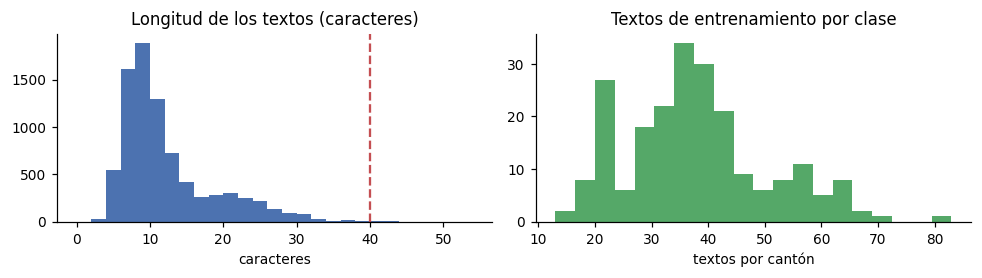

'CRNEL MARCELINO MARIDUEA'       -> [5, 20, 16, 7, 14, 2, 15, 3, 20, 5, 7, 14, 11, 16, 17, 2, 15, 3, 20, 11, 6, 23, 7, 3, 0, 0]
'N LA CONCORDIA'                 -> [16, 2, 14, 3, 2, 5, 17, 16, 5, 17, 20, 6, 11, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
'PIAS'                           -> [18, 11, 3, 21, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:
# Tras `nrm` el alfabeto es cerrado: espacio, A-Z y 0-9 (los demás símbolos ya se convirtieron en espacio). 0 = relleno, 1 = desconocido (no ocurre).
ALFABETO = " ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
vocab = ["<PAD>", "<UNK>"] + list(ALFABETO); CH2I = {c: i for i, c in enumerate(vocab)}; V = len(vocab)
def codificar(textos, maxlen=PAR["MAXLEN"]):
    X = np.zeros((len(textos), maxlen), dtype="int32")
    for i, t in enumerate(textos):
        ids = [CH2I.get(ch, 1) for ch in t][:maxlen]; X[i, :len(ids)] = ids
    return X
D = dict(corpus=corpus, tr=tr, va=va, te=te, Xtr=codificar(tr.texto), Xva=codificar(va.texto), Xte=codificar(te.texto), ytr=tr.y.values, yva=va.y.values, yte=te.y.values)
Xre, yre = codificar(real.x), real.y.map(C2I).values
lon = tr.texto.str.len()
RES["ficha"] = dict(corpus=int(len(corpus)), train=int(len(tr)), val=int(len(va)), test_sintetico=int(len(te)), test_real=int(len(real)),
                    vocabulario=int(V), maxlen=PAR["MAXLEN"], long_media=round(float(lon.mean()), 1), long_p95=int(lon.quantile(0.95)), long_max=int(lon.max()),
                    truncados_pct=round(float((lon > PAR["MAXLEN"]).mean() * 100), 2), clases=NC)
ficha = pd.Series({"Cantones oficiales / clases": f"{RES['datos']['cantones_oficiales']} / {NC}", "Textos del corpus (únicos)": len(corpus), "Entrenamiento / validación / prueba sintética": f"{len(tr)} / {len(va)} / {len(te)}",
                   "Prueba real (cadenas distintas)": len(real), "Vocabulario (caracteres)": V, "Longitud de texto: media / p95 / máx": f"{lon.mean():.1f} / {int(lon.quantile(0.95))} / {int(lon.max())}",
                   "Longitud fija de secuencia (MAXLEN)": PAR["MAXLEN"], "Textos truncados (%)": round(float((lon > PAR["MAXLEN"]).mean() * 100), 2), "Variable objetivo": "cantón oficial (entero 0-218)", "Salida": "219 probabilidades (softmax)"}, name="valor")
display(ficha.to_frame())
os.makedirs("figs", exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6)); ax[0].hist(lon, bins=range(0, 55, 2), color="#4C72B0"); ax[0].axvline(PAR["MAXLEN"], c="#C44E52", ls="--"); ax[0].set_title("Longitud de los textos (caracteres)"); ax[0].set_xlabel("caracteres")
ax[1].hist(tr.groupby("clase").size(), bins=20, color="#55A868"); ax[1].set_title("Textos de entrenamiento por clase"); ax[1].set_xlabel("textos por cantón"); plt.tight_layout(); plt.savefig("figs/fig_datos.png", dpi=200); plt.show()
for e in ["CRNEL MARCELINO MARIDUEA", "N LA CONCORDIA", "PIAS"]: print(f"{e!r:32} -> {codificar([e])[0][:26].tolist()}")

## 4. Línea base sin aprendizaje: distancia de edición
Antes de entrenar una red hay que comparar contra la solución trivial: asignar cada texto al nombre oficial (o alias de cabecera) más parecido por **distancia de Levenshtein**. Si la red no la mejora, no se justifica.

In [6]:
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein
cand_txt = [b for b, _ in fuentes]; cand_cls = np.array([C2I[c] for _, c in fuentes])
def base_edicion(textos):
    return np.array([cand_cls[process.extractOne(t, cand_txt, scorer=Levenshtein.normalized_similarity)[2]] for t in textos])

def metr_sint(y, yp):
    p, r, f, _ = precision_recall_fscore_support(y, yp, labels=range(NC), average="macro", zero_division=0)
    return dict(acc=float(accuracy_score(y, yp)), precision=float(p), recall=float(r), f1=float(f))
def metr_real(yp):
    ok = (yp == yre); w = real.registros.values
    return dict(acc=float(ok.mean()), aciertos=int(ok.sum()), n=int(len(ok)), acc_ponderada=float((ok * w).sum() / w.sum()))

yp_b_te, yp_b_re = base_edicion(D["te"].texto.tolist()), base_edicion(real.x)
RES["baseline"] = dict(sintetico=metr_sint(D["yte"], yp_b_te), real=metr_real(yp_b_re))
print("Línea base (distancia de edición) -> sintético:", {k: round(v, 3) for k, v in RES["baseline"]["sintetico"].items()}, "| real:", RES["baseline"]["real"])

Línea base (distancia de edición) -> sintético: {'acc': 0.94, 'precision': 0.972, 'recall': 0.928, 'f1': 0.942} | real: {'acc': 1.0, 'aciertos': 38, 'n': 38, 'acc_ponderada': 1.0}


## 5. Arquitecturas implementadas desde cero (rúbrica 4)
Ambas se construyen capa por capa con `keras.layers`, con pesos inicializados al azar (ningún modelo preentrenado).

**A. BiGRU.** `Embedding(39→64, mask_zero)` → `Bidirectional(GRU(96, return_sequences))` → `Bidirectional(GRU(96))` → `Dropout(0,3)` → `Dense(256, ReLU)` → `Dropout(0,3)` → `Dense(219, softmax)`.
La GRU usa compuertas de actualización y reinicio (menos parámetros que una LSTM, adecuada para secuencias de ≤40 pasos); el sentido inverso permite que «CRNEL…» use el final del texto para decidir. La máscara hace que el relleno no cuente.

**B. Transformer encoder.** `Embedding(39→64)` + **codificación posicional sinusoidal** → 2 × [`MultiHeadAttention`(4 cabezas, `key_dim`=16) + residual + `LayerNorm` → `Dense(128, ReLU)`→`Dense(64)` + residual + `LayerNorm`] → **promedio enmascarado** → `Dropout(0,3)` → `Dense(256, ReLU)` → `Dense(219, softmax)`. El mecanismo de atención compara todos los pares de caracteres; sin recurrencia, el orden se inyecta con la codificación posicional. La máscara de relleno evita que la atención mire los ceros.

In [7]:
class CodificacionPosicional(layers.Layer):
    """Embedding de caracteres + codificación posicional sinusoidal (Vaswani et al., 2017)."""
    def __init__(self, vocab, d, maxlen, **kw):
        super().__init__(**kw); self.d, self.maxlen = d, maxlen; self.emb = layers.Embedding(vocab, d)
        pos = np.arange(maxlen)[:, None]; i = np.arange(d)[None, :]; ang = pos / np.power(10000.0, (2 * (i // 2)) / d)
        pe = np.where(i % 2 == 0, np.sin(ang), np.cos(ang)).astype("float32"); self.pe = tf.constant(pe[None])
    def call(self, x): return self.emb(x) * float(np.sqrt(self.d)) + self.pe[:, :tf.shape(x)[1]]

class BloqueTransformer(layers.Layer):
    def __init__(self, d, cabezas, ff, drop, **kw):
        super().__init__(**kw); self.att = layers.MultiHeadAttention(num_heads=cabezas, key_dim=d // cabezas)
        self.ffn = keras.Sequential([layers.Dense(ff, activation="relu"), layers.Dense(d)])
        self.n1, self.n2 = layers.LayerNormalization(epsilon=1e-6), layers.LayerNormalization(epsilon=1e-6); self.d1, self.d2 = layers.Dropout(drop), layers.Dropout(drop)
    def call(self, x, ids, training=False):
        mask = tf.not_equal(ids, 0); am = tf.logical_and(mask[:, :, None], mask[:, None, :])                 # (B,T,T): ningún carácter atiende al relleno
        x = self.n1(x + self.d1(self.att(x, x, attention_mask=am), training=training))
        return self.n2(x + self.d2(self.ffn(x), training=training))

class PromedioEnmascarado(layers.Layer):
    def call(self, x, ids):
        m = tf.cast(tf.not_equal(ids, 0), x.dtype)[:, :, None]; return tf.reduce_sum(x * m, 1) / tf.maximum(tf.reduce_sum(m, 1), 1.0)

def construir(nombre):
    entrada = keras.Input((PAR["MAXLEN"],), dtype="int32")
    if nombre == "BiGRU":
        x = layers.Embedding(V, PAR["EMB"], mask_zero=True)(entrada)
        x = layers.Bidirectional(layers.GRU(PAR["GRU"], return_sequences=True))(x)
        x = layers.Bidirectional(layers.GRU(PAR["GRU"]))(x)
    else:
        x = CodificacionPosicional(V, PAR["D_MODELO"], PAR["MAXLEN"])(entrada)
        for _ in range(PAR["BLOQUES"]): x = BloqueTransformer(PAR["D_MODELO"], PAR["CABEZAS"], PAR["FF"], 0.1)(x, entrada)
        x = PromedioEnmascarado()(x, entrada)
    x = layers.Dropout(PAR["DROPOUT"])(x); x = layers.Dense(256, activation="relu")(x); x = layers.Dropout(PAR["DROPOUT"])(x)
    return keras.Model(entrada, layers.Dense(NC, activation="softmax")(x), name=nombre)

for n in ("BiGRU", "Transformer"):
    m = construir(n); print(n, "->", f"{m.count_params():,} parámetros"); RES.setdefault("parametros_modelo", {})[n] = int(m.count_params())
construir("Transformer").summary()

BiGRU -> 368,539 parámetros
Transformer -> 142,363 parámetros


Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ codificacion_posic… │ (None, 40, 64)    │      2,496 │ input_layer_4[0]… │
│ (CodificacionPosic… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bloque_transformer… │ (None, 40, 64)    │     33,472 │ codificacion_pos… │
│ (BloqueTransformer) │                   │            │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bloque_transformer… │ (None, 40, 64)    │     33,472 │ bloque_transform… │
│ (BloqueTransformer) │                   │            │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ promedio_enmascara… │ (None, 64)        │          0 │ bloque_transform… │
│ (PromedioEnmascara… │                   │            │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 64)        │          0 │ promedio_enmasca… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 256)       │     16,640 │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 256)       │          0 │ dense_12[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 219)       │     56,283 │ dropout_17[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 142,363 (556.11 KB)

 Trainable params: 142,363 (556.11 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Configuración y entrenamiento (rúbrica 5)
| Elemento | Valor | Justificación |
|---|---|---|
| Pérdida | `sparse_categorical_crossentropy` | clasificación multiclase (219) con etiqueta entera; evita la matriz one-hot |
| Optimizador | Adam, lr = 1e-3 | adaptativo, estándar en secuencias; sin ajuste fino de lr |
| Batch / épocas | 128 / hasta 60 | ~8.200 muestras: ≈64 pasos por época; el tope rara vez se alcanza |
| `EarlyStopping` | `val_loss`, paciencia 6, restaura el mejor modelo | evita sobreajuste y tiempo perdido |
| `ReduceLROnPlateau` | factor 0,5, paciencia 2 | afina cuando la pérdida de validación se estanca |
| Regularización | Dropout 0,3 (0,1 dentro de los bloques) | el corpus es sintético y la red puede memorizar los patrones de ruido |

In [8]:
def entrenar(nombre, semilla, datos=None, verbose=0):
    datos = datos or D; fijar_semilla(semilla); m = construir(nombre)
    m.compile(optimizer=keras.optimizers.Adam(PAR["LR"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PAR["PACIENCIA"], restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
    t0 = time.time(); h = m.fit(datos["Xtr"], datos["ytr"], validation_data=(datos["Xva"], datos["yva"]), epochs=PAR["EPOCAS"], batch_size=PAR["BATCH"], callbacks=cb, verbose=verbose)
    return m, h.history, time.time() - t0

def evaluar_modelo(m, datos=None):
    datos = datos or D; p_te = m.predict(datos["Xte"], verbose=0); p_re = m.predict(Xre, verbose=0)
    return dict(sintetico=metr_sint(datos["yte"], p_te.argmax(1)), real=metr_real(p_re.argmax(1))), p_te, p_re

PRINCIPAL = {}
for nombre in ("BiGRU", "Transformer"):
    m, hist, seg = entrenar(nombre, PAR["SEMILLA"]); met, p_te, p_re = evaluar_modelo(m)
    PRINCIPAL[nombre] = dict(modelo=m, hist=hist, p_te=p_te, p_re=p_re, met=met)
    best = int(np.argmin(hist["val_loss"]))
    print(f"{nombre}: {len(hist['loss'])} épocas (mejor {best + 1}), {seg:.0f} s | val_acc {hist['val_accuracy'][best]:.3f} | sintético {met['sintetico']['acc']:.3f} | real {met['real']['aciertos']}/{met['real']['n']}")
    RES.setdefault("entrenamiento", {})[nombre] = dict(epocas=len(hist["loss"]), mejor_epoca=best + 1, segundos=round(seg), loss_train=round(float(hist["loss"][best]), 4), loss_val=round(float(hist["val_loss"][best]), 4),
                                                       acc_train=round(float(hist["accuracy"][best]), 4), acc_val=round(float(hist["val_accuracy"][best]), 4), lr_final=float(hist["learning_rate"][-1]) if "learning_rate" in hist else None)
    RES.setdefault("principal", {})[nombre] = met

BiGRU: 44 épocas (mejor 38), 60 s | val_acc 0.960 | sintético 0.967 | real 38/38
Transformer: 56 épocas (mejor 50), 60 s | val_acc 0.956 | sintético 0.962 | real 36/38


## 7. Evaluación y análisis de rendimiento (rúbrica 6)
Dos pruebas con propósitos distintos:
* **Prueba sintética** (1.759 textos con ruido nunca vistos): mide la robustez frente al ruido del generador. Es optimista, porque el ruido es del mismo tipo que el de entrenamiento.
* **Prueba real** (38 cadenas distintas del diccionario manual, 19.104 registros): ruido real del data lake, sin intervención en el entrenamiento. Es la medida que importa, pero **es pequeña**: un acierto de diferencia son 2,6 puntos.

Métricas: *accuracy*, y precisión, recall y F1 **macro** (promedio sobre las 219 clases, para que los cantones raros pesen igual que los comunes).

In [9]:
filas = [("Distancia de edición (sin aprendizaje)", RES["baseline"])] + [(n, RES["principal"][n]) for n in ("BiGRU", "Transformer")]
tabla = pd.DataFrame([{"Modelo": n, "Acc. sintética": r["sintetico"]["acc"], "Precisión macro": r["sintetico"]["precision"], "Recall macro": r["sintetico"]["recall"], "F1 macro": r["sintetico"]["f1"],
                       "Real: aciertos": f'{r["real"]["aciertos"]}/{r["real"]["n"]}', "Real: acc. ponderada": r["real"]["acc_ponderada"]} for n, r in filas]).set_index("Modelo")
display(tabla.round(3))

,Acc. sintética,Precisión macro,Recall macro,F1 macro,Real: aciertos,Real: acc. ponderada
Modelo,,,,,,
Distancia de edición (sin aprendizaje),0.940,0.972,0.928,0.942,38/38,1.000
BiGRU,0.967,0.967,0.966,0.963,38/38,1.000
Transformer,0.962,0.960,0.957,0.955,36/38,0.998


### 7.1 Curvas de entrenamiento y sobreajuste
La curva de entrenamiento y la de validación permiten ver si la red memoriza el corpus. `EarlyStopping` restaura los pesos de la mejor época.

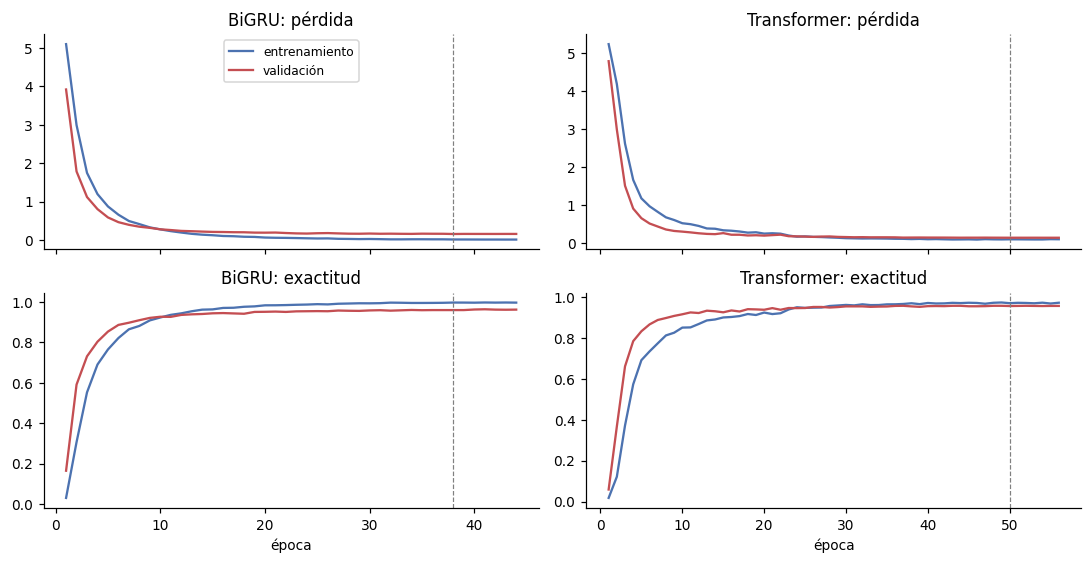

BiGRU: mejor época 38 de 44 | exactitud train 0.997 vs val 0.960 | pérdida train 0.017 vs val 0.159
Transformer: mejor época 50 de 56 | exactitud train 0.970 vs val 0.956 | pérdida train 0.098 vs val 0.139


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5.2), sharex="col")
for j, n in enumerate(("BiGRU", "Transformer")):
    h = PRINCIPAL[n]["hist"]; ep = np.arange(1, len(h["loss"]) + 1); best = int(np.argmin(h["val_loss"])) + 1
    axes[0, j].plot(ep, h["loss"], label="entrenamiento", c="#4C72B0"); axes[0, j].plot(ep, h["val_loss"], label="validación", c="#C44E52"); axes[0, j].set_title(f"{n}: pérdida")
    axes[1, j].plot(ep, h["accuracy"], c="#4C72B0"); axes[1, j].plot(ep, h["val_accuracy"], c="#C44E52"); axes[1, j].set_title(f"{n}: exactitud"); axes[1, j].set_xlabel("época")
    for a in axes[:, j]: a.axvline(best, c="gray", ls="--", lw=0.8)
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig("figs/fig_curvas.png", dpi=200); plt.show()
for n in ("BiGRU", "Transformer"):
    e = RES["entrenamiento"][n]; print(f"{n}: mejor época {e['mejor_epoca']} de {e['epocas']} | exactitud train {e['acc_train']:.3f} vs val {e['acc_val']:.3f} | pérdida train {e['loss_train']:.3f} vs val {e['loss_val']:.3f}")

### 7.2 Matriz de confusión: qué cantones confunde y por qué
Con 219 clases una matriz completa no se puede leer. Se cuentan los pares (cantón real → cantón predicho) más frecuentes en los errores de la prueba sintética del mejor modelo y se dibuja la matriz solo para los cantones involucrados.

,cantón real,predicho,errores
0,GUAYAQUIL,NANGARITZA,2
1,CUYABENO,CHAMBO,2
2,ESPEJO,SANTA ISABEL,1
3,CHINCHIPE,BABA,1
4,MANTA,CUMANDA,1
5,DISTRITO METROPOLITANO DE QUITO,AGUARICO,1
6,LATACUNGA,VALENCIA,1
7,PASTAZA,SANTA CLARA,1
8,PUJILI,CENTINELA DEL CONDOR,1
9,GUANO,GIRON,1


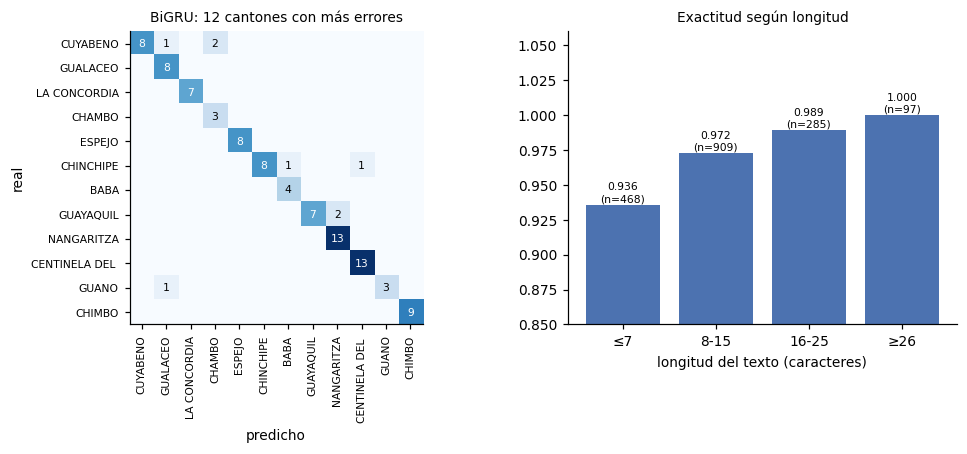

{'modelo': 'BiGRU', 'n_errores': 58, 'n_test': 1759, 'pct_errores_textos_cortos': 51.7, 'pct_textos_cortos_en_test': 26.6, 'acc_textos_cortos': 0.936, 'acc_textos_largos': 0.978, 'top_pares': [{'real': 'GUAYAQUIL', 'predicho': 'NANGARITZA', 'n': 2}, {'real': 'CUYABENO', 'predicho': 'CHAMBO', 'n': 2}, {'real': 'ESPEJO', 'predicho': 'SANTA ISABEL', 'n': 1}, {'real': 'CHINCHIPE', 'predicho': 'BABA', 'n': 1}, {'real': 'MANTA', 'predicho': 'CUMANDA', 'n': 1}]}
Ejemplos de error:


,texto,real,predicho,confianza
0,E ANRGEL,ESPEJO,SANTA ISABEL,0.91
1,ZLMBA,CHINCHIPE,BABA,0.19
2,GAD MANNA,MANTA,CUMANDA,0.73
3,QAITO,DISTRITO METROPOLITANO DE QUITO,AGUARICO,0.53
4,LATALUNGA,LATACUNGA,VALENCIA,0.45
5,GUAYAQUIG,GUAYAQUIL,NANGARITZA,0.71
6,ASTAZA,PASTAZA,SANTA CLARA,0.71
7,PUJII,PUJILI,CENTINELA DEL CONDOR,0.77
8,GURNO,GUANO,GIRON,0.46
9,SUCMBIO,SUCUMBIOS,CHIMBO,0.47


In [11]:
mejor = max(("BiGRU", "Transformer"), key=lambda n: RES["principal"][n]["sintetico"]["f1"]); RES["mejor_modelo"] = mejor
p_te = PRINCIPAL[mejor]["p_te"]; yp = p_te.argmax(1); yt = D["yte"]; err = np.where(yp != yt)[0]
pares = collections.Counter((CLASES[yt[i]], CLASES[yp[i]]) for i in err)
top_pares = pares.most_common(10); display(pd.DataFrame([(a, b, n) for (a, b), n in top_pares], columns=["cantón real", "predicho", "errores"]))
inv = collections.Counter(c for (a, b), n in pares.items() for c in (a, b) for _ in range(n)); sel = [c for c, _ in inv.most_common(12)]
M = confusion_matrix([CLASES[i] for i in yt], [CLASES[i] for i in yp], labels=sel)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.2), gridspec_kw={"width_ratios": [1.35, 1]}); ax.imshow(M, cmap="Blues")
ax.set_xticks(range(len(sel))); ax.set_xticklabels([s[:14] for s in sel], rotation=90, fontsize=7); ax.set_yticks(range(len(sel))); ax.set_yticklabels([s[:14] for s in sel], fontsize=7)
for i in range(len(sel)):
    for k in range(len(sel)):
        if M[i, k]: ax.text(k, i, M[i, k], ha="center", va="center", fontsize=7, color="white" if M[i, k] > M.max() / 2 else "black")
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(f"{mejor}: 12 cantones con más errores", fontsize=9)
largo = np.array([len(t) for t in D["te"].texto]); cubos = [(0, 7, "≤7"), (8, 15, "8-15"), (16, 25, "16-25"), (26, 99, "≥26")]
acc_l = [(yp[(largo >= a) & (largo <= b)] == yt[(largo >= a) & (largo <= b)]).mean() for a, b, _ in cubos]; n_l = [int(((largo >= a) & (largo <= b)).sum()) for a, b, _ in cubos]
ax2.bar([c[2] for c in cubos], acc_l, color="#4C72B0"); ax2.set_ylim(0.85, 1.06); ax2.set_xlabel("longitud del texto (caracteres)"); ax2.set_title("Exactitud según longitud", fontsize=9)
for i, (v, n) in enumerate(zip(acc_l, n_l)): ax2.text(i, v + 0.002, f"{v:.3f}\n(n={n})", ha="center", fontsize=7)
plt.tight_layout(); plt.savefig("figs/fig_confusion.png", dpi=200); plt.show()
RES["acc_por_longitud"] = {c[2]: dict(acc=round(float(v), 3), n=n) for c, v, n in zip(cubos, acc_l, n_l)}
corto = largo < 8
RES["errores"] = dict(modelo=mejor, n_errores=int(len(err)), n_test=int(len(yt)), pct_errores_textos_cortos=round(float(corto[err].mean() * 100), 1), pct_textos_cortos_en_test=round(float(corto.mean() * 100), 1),
                      acc_textos_cortos=round(float((yp[corto] == yt[corto]).mean()), 3), acc_textos_largos=round(float((yp[~corto] == yt[~corto]).mean()), 3),
                      top_pares=[dict(real=a, predicho=b, n=int(n)) for (a, b), n in top_pares[:5]])
print(RES["errores"])
print("Ejemplos de error:"); display(pd.DataFrame([(D["te"].texto[i], CLASES[yt[i]], CLASES[yp[i]], round(float(p_te[i].max()), 2)) for i in err[:10]], columns=["texto", "real", "predicho", "confianza"]))

### 7.3 Ejemplos reales: aciertos y errores
Las 38 cadenas del diccionario manual con la predicción de cada método. «Confianza» es la probabilidad máxima del *softmax* del mejor modelo.

In [12]:
pr = PRINCIPAL[mejor]["p_re"]; ejem = pd.DataFrame({"texto crudo (normalizado)": real.x, "cantón oficial": real.y, "BiGRU": [CLASES[i] for i in PRINCIPAL["BiGRU"]["p_re"].argmax(1)],
                                                   "Transformer": [CLASES[i] for i in PRINCIPAL["Transformer"]["p_re"].argmax(1)], "dist. edición": [CLASES[i] for i in yp_b_re],
                                                   "conf. " + mejor: pr.max(1).round(2), "registros": real.registros})
ejem["ok " + mejor] = ejem[mejor] == ejem["cantón oficial"]
RES["real_errores"] = {n: [dict(texto=r.x, esperado=r.y, predicho=CLASES[int(PRINCIPAL[n]["p_re"][i].argmax())], conf=round(float(PRINCIPAL[n]["p_re"][i].max()), 2)) for i, r in real.iterrows() if PRINCIPAL[n]["p_re"][i].argmax() != yre[i]] for n in ("BiGRU", "Transformer")}
display(ejem.sort_values("registros", ascending=False).head(12)); print("Errores reales:", RES["real_errores"])

,texto crudo (normalizado),cantón oficial,BiGRU,Transformer,dist. edición,conf. BiGRU,registros,ok BiGRU
27,PUERTO FRANCISCO DE ORELLANA,FRANCISCO DE ORELLANA,FRANCISCO DE ORELLANA,FRANCISCO DE ORELLANA,FRANCISCO DE ORELLANA,1.0,5250,True
28,RIO VERDE,RIOVERDE,RIOVERDE,RIOVERDE,RIOVERDE,1.0,2979,True
24,PUEBLO VIEJO,PUEBLOVIEJO,PUEBLOVIEJO,PUEBLOVIEJO,PUEBLOVIEJO,1.0,2780,True
13,GNRAL ANTONIO ELIZALDE,GENERAL ANTONIO ELIZALDE,GENERAL ANTONIO ELIZALDE,GENERAL ANTONIO ELIZALDE,GENERAL ANTONIO ELIZALDE,1.0,2543,True
10,CRNEL MARCELINO MARIDUEA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,1.0,1867,True
15,JOYA DE LOS SACHAS,LA JOYA DE LOS SACHAS,LA JOYA DE LOS SACHAS,LA JOYA DE LOS SACHAS,LA JOYA DE LOS SACHAS,1.0,827,True
6,CAMILO PONCE ENRIQUE,CAMILO PONCE ENRIQUEZ,CAMILO PONCE ENRIQUEZ,CAMILO PONCE ENRIQUEZ,CAMILO PONCE ENRIQUEZ,1.0,739,True
12,CRNEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,CORONEL MARCELINO MARIDUENA,1.0,719,True
20,N LA CONCORDIA,LA CONCORDIA,LA CONCORDIA,LA CONCORDIA,LA CONCORDIA,1.0,642,True
17,LOGROO,LOGRONO,LOGRONO,LOGRONO,LOGRONO,1.0,224,True


Errores reales: {'BiGRU': [], 'Transformer': [{'texto': 'A BAQUERIZO MORENO', 'esperado': 'ALFREDO BAQUERIZO MORENO', 'predicho': 'SAN CRISTOBAL', 'conf': 0.89}, {'texto': 'TIZALEO', 'esperado': 'TISALEO', 'predicho': 'ZAPOTILLO', 'conf': 0.54}]}


### 7.4 Secuencias procesadas
Cómo ve la red tres textos reales: índices de carácter con relleno a 40 posiciones (blanco = relleno que la máscara ignora).

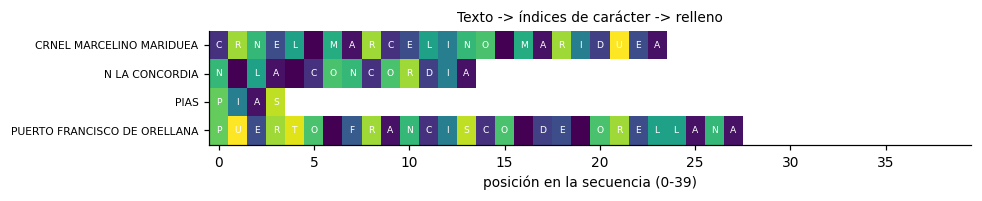

In [13]:
muestra = ["CRNEL MARCELINO MARIDUEA", "N LA CONCORDIA", "PIAS", "PUERTO FRANCISCO DE ORELLANA"]; Xm = codificar(muestra)
fig, ax = plt.subplots(figsize=(9, 1.9)); ax.imshow(np.ma.masked_where(Xm == 0, Xm), cmap="viridis", aspect="auto"); ax.set_yticks(range(len(muestra))); ax.set_yticklabels(muestra, fontsize=7)
for i, t in enumerate(muestra):
    for k, ch in enumerate(t[:PAR["MAXLEN"]]): ax.text(k, i, ch, ha="center", va="center", fontsize=6, color="white")
ax.set_xlabel("posición en la secuencia (0-39)"); ax.set_title("Texto -> índices de carácter -> relleno", fontsize=9); plt.tight_layout(); plt.savefig("figs/fig_secuencias.png", dpi=200); plt.show()

### 7.5 Textos del data lake sin etiqueta: ¿hay que revisarlos?
En el lake hay otros textos de cantón que ni las reglas ni el diccionario resuelven (códigos numéricos aparte). No tienen verdad de terreno, así que **no se calcula exactitud**: se muestra qué propone cada método y con qué confianza, para decidir cuáles revisar a mano. Se mira además si la confianza del *softmax* sirve como filtro de rechazo (umbral `UMBRAL_CONF`).

In [14]:
ya = set(CLASES) | set(alias) | set(real.x); res_lake = terr.groupby("vn").n.sum().reset_index()
libres = res_lake[~res_lake.vn.isin(ya) & ~res_lake.vn.str.fullmatch(r"\d+") & (res_lake.vn.str.len() > 1)].sort_values("n", ascending=False).reset_index(drop=True)
pl = PRINCIPAL[mejor]["modelo"].predict(codificar(libres.vn), verbose=0)
libres["propuesta " + mejor] = [CLASES[i] for i in pl.argmax(1)]; libres["confianza"] = pl.max(1).round(2); libres["dist. edición"] = [CLASES[i] for i in base_edicion(libres.vn)]
libres["coinciden"] = libres["propuesta " + mejor] == libres["dist. edición"]
RES["sin_etiqueta"] = dict(textos=int(len(libres)), registros=int(libres.n.sum()), conf_alta=int((libres.confianza >= PAR["UMBRAL_CONF"]).sum()), coinciden=int(libres.coinciden.sum()),
                         ejemplos=[dict(texto=str(r.vn), registros=int(r.n), propuesta=str(r["propuesta " + mejor]), conf=float(r.confianza)) for _, r in libres.head(8).iterrows()])
print(RES["sin_etiqueta"]); display(libres.head(12))
ok_conf = p_te.max(1) >= PAR["UMBRAL_CONF"]
RES["umbral"] = dict(umbral=PAR["UMBRAL_CONF"], cobertura_sintetico=round(float(ok_conf.mean()), 3), acc_sobre_umbral=round(float((yp[ok_conf] == yt[ok_conf]).mean()), 3), acc_bajo_umbral=round(float((yp[~ok_conf] == yt[~ok_conf]).mean()), 3))
print("Umbral de confianza (prueba sintética):", RES["umbral"])

{'textos': 85, 'registros': 102989, 'conf_alta': 73, 'coinciden': 26, 'ejemplos': [{'texto': 'ORELLANA', 'registros': 39143, 'propuesta': 'QUILANGA', 'conf': 0.27000001072883606}, {'texto': 'QUITO NOROCCIDENTE', 'registros': 27386, 'propuesta': 'ROCAFUERTE', 'conf': 0.5099999904632568}, {'texto': 'GENERAL ELIZALDE BUCAY', 'registros': 8424, 'propuesta': 'CENTINELA DEL CONDOR', 'conf': 0.25999999046325684}, {'texto': 'ALFREDO BAQUERIZO', 'registros': 6624, 'propuesta': 'ALFREDO BAQUERIZO MORENO', 'conf': 0.9900000095367432}, {'texto': 'EMPALME', 'registros': 6350, 'propuesta': 'EL EMPALME', 'conf': 1.0}, {'texto': 'SANTO DOMINGO DE LOS TSACHILAS', 'registros': 2694, 'propuesta': 'CASCALES', 'conf': 0.5099999904632568}, {'texto': 'EXTRANJERO', 'registros': 2478, 'propuesta': 'TISALEO', 'conf': 0.7200000286102295}, {'texto': 'CANTON QUINSALOMA', 'registros': 2220, 'propuesta': 'QUINSALOMA', 'conf': 1.0}]}


,vn,n,propuesta BiGRU,confianza,dist. edición,coinciden
0,ORELLANA,39143,QUILANGA,0.27,ARENILLAS,False
1,QUITO NOROCCIDENTE,27386,ROCAFUERTE,0.51,AGUARICO,False
2,GENERAL ELIZALDE BUCAY,8424,CENTINELA DEL CONDOR,0.26,PLAYAS,False
3,ALFREDO BAQUERIZO,6624,ALFREDO BAQUERIZO MORENO,0.99,ALFREDO BAQUERIZO MORENO,True
4,EMPALME,6350,EL EMPALME,1.00,EL EMPALME,True
5,SANTO DOMINGO DE LOS TSACHILAS,2694,CASCALES,0.51,SANTO DOMINGO,False
6,EXTRANJERO,2478,TISALEO,0.72,NARANJITO,False
7,CANTON QUINSALOMA,2220,QUINSALOMA,1.00,QUINSALOMA,True
8,SALITRE URBINA JADO,1697,SAN FERNANDO,0.88,SAN FERNANDO,True
9,NA,1463,MANTA,0.87,ONA,False


Umbral de confianza (prueba sintética): {'umbral': 0.5, 'cobertura_sintetico': 0.99, 'acc_sobre_umbral': 0.974, 'acc_bajo_umbral': 0.294}


## 8. Conclusiones y proyección a la semana 3 (rúbrica 8)
Las cifras de este cuaderno se guardan en `resultados_W2.json` y el informe se genera desde ese archivo, de modo que ambos coinciden. Las conclusiones con números están en la sección 8 del informe; aquí quedan las ideas de fondo:
* **Qué se aprendió de construir «desde cero».** Se diseñaron capa por capa una BiGRU y un Transformer (atención multi-cabeza, codificación posicional, máscara de relleno, residuales y normalización). La BiGRU quedó ligeramente por delante del Transformer en la prueba sintética (con más cómputo por época); con tan pocos datos y secuencias tan cortas la atención no muestra ventaja, y la diferencia en la prueba real es de un par de cadenas, es decir, no concluyente.
* **La línea base importa.** La distancia de edición ya es muy fuerte para estos errores; una red solo se justifica si la supera en robustez, y aquí lo hace poco. Para la tesis, la conclusión práctica es que **la homologación fuzzy es viable** y puede sustituir al diccionario manual.
* **Límite del enfoque cerrado.** Ninguno de los métodos sabe decir «esto no es un cantón» (EXTRANJERO, NA, zonas o provincias en el campo cantón). La confianza del *softmax* no sirve como filtro, porque esos textos reciben confianzas altas; haría falta una clase «no es cantón» o una verificación contra el catálogo, y revisión humana.

**Preparación de la semana 3 (identificación preliminar, sin implementar).** Candidatos preentrenados para comparar con estos resultados sobre las mismas particiones y la misma prueba real:
1. **BETO** (`dccuchile/bert-base-spanish-wwm-cased`) o **BERT multilingüe**, con ajuste fino y una cabeza de 219 clases. Riesgo esperado: su tokenizador por subpalabras fragmenta los textos mal escritos.
2. **ByT5** (`google/byt5-small`) o **CANINE**: modelos a nivel de byte/carácter, naturales para este ruido.
3. Como alternativa ligera, *embeddings* de oraciones (p. ej. LaBSE) con vecino más cercano contra el catálogo.
Existen modelos preentrenados de texto en español, por lo que no se requiere un ejercicio adicional según la nota de la guía.

In [15]:
os.makedirs("modelos", exist_ok=True)
for n in ("BiGRU", "Transformer"): PRINCIPAL[n]["modelo"].save(f"modelos/{n.lower()}_semilla{PAR['SEMILLA']}.keras")
ejem.to_csv("predicciones_prueba_real.csv", index=False, encoding="utf-8-sig"); libres.to_csv("predicciones_textos_sin_etiqueta.csv", index=False, encoding="utf-8-sig")
json.dump(RES, open("resultados_W2.json", "w"), indent=1, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("JSON y modelos guardados")

JSON y modelos guardados
